# Demand forecast evaluation (AI-001..AI-003)

Holdout results for the **moving-average baseline** and the **global gradient-boosting model**,
plus the forecasts of the two demo products. Everything here is computed from the committed
synthetic ledger (`tests/fixtures`), the same data the tests use, with fixed seeds, so a rerun
gives the same numbers. **The data is synthetic**: results show that the pipeline works and how
the two models compare on this data, not what accuracy a real plant would see.

**Protocol.** The last 14 days of every series are held out. The baseline window (7 or 14 days) is
chosen on the training days only; the ML model is trained on days up to the day before the holdout
only; both forecast the full 14 days from that origin. Per series the model with the lower holdout
MAE is selected (AI-003). Because that choice is made on the same 14 noisy days it is scored on, a
**nested estimate** repeats the choice on the *earlier* 14 days and scores it on the untouched holdout.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent                      # ai-service/
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

ACTUAL, BASELINE, ML, SELECTED = "#444444", "#0072B2", "#D55E00", "#009E73"   # colour-blind safe
FIXTURES = ROOT / "tests" / "fixtures"

In [2]:
import json
from app.data.series import daily_demand, series_map
from app.data.sources import CsvSource
from app.forecasting.evaluate import evaluate_forecasting

source = CsvSource(FIXTURES)
products = source.products().set_index("id")["sku"]
profiles = json.loads((FIXTURES / "scenarios.json").read_text())
steered = {sku for sku, profile in profiles["profiles"].items() if profile in profiles["steeredProfiles"]}

series = series_map(daily_demand(source.ledger(), tz_offset_hours=6))
label = lambda key: f"{products[key[0]]} @ {'MAIN' if key[1] == 1 else 'DEPOT'}"
lengths = pd.Series({k: len(v) for k, v in series.items()})
print(f"{len(series)} series, {lengths.min()}-{lengths.max()} days each, ending {max(v.index[-1] for v in series.values()).date()}")
print(f"average daily demand per series: {np.mean([v.mean() for v in series.values()]):.1f} units "
      f"(range {min(v.mean() for v in series.values()):.1f} - {max(v.mean() for v in series.values()):.1f})")

24 series, 90-90 days each, ending 2026-11-01
average daily demand per series: 2.9 units (range 0.3 - 12.0)


## 1. Overall holdout accuracy

In [3]:
result = evaluate_forecasting(series)
names = {"baseline": "Moving average (baseline)", "ml": "ML (global model)", "selected": "Selected per series (AI-003)",
         "nested_selected": "Selected, nested estimate (honest)", "seasonal_naive": "Seasonal naive (reference)"}
overall = pd.DataFrame({names[k]: s.as_dict() for k, s in result.summaries.items()}).T
overall = overall.rename(columns={"macro_mae": "MAE (mean of series)", "micro_mae": "MAE (pooled days)", "wape": "WAPE", "bias": "bias (forecast - actual)"}).drop(columns="series")
print(f"holdout {result.holdout_start.date()} .. {result.holdout_end.date()}   |   {len(result.per_series)} series   |   ML available for {result.ml_series}   |   {result.model_samples:,} training samples")
overall.round(3)

holdout 2026-10-19 .. 2026-11-01   |   24 series   |   ML available for 24   |   24,120 training samples


,MAE (mean of series),MAE (pooled days),WAPE,bias (forecast - actual)
Moving average (baseline),1.536,1.536,0.500,0.033
ML (global model),1.317,1.317,0.428,-0.123
Selected per series (AI-003),1.294,1.294,0.421,-0.130
"Selected, nested estimate (honest)",1.414,1.414,0.460,-0.062
Seasonal naive (reference),1.777,1.777,0.578,0.039


In [4]:
s = result.summaries
b, m, sel, nested = s["baseline"].macro_mae, s["ml"].macro_mae, s["selected"].macro_mae, s["nested_selected"].macro_mae
print(f"ML cuts the baseline MAE by {100 * (1 - m / b):.1f}% ({b:.3f} -> {m:.3f}).")
print(f"The AI-003 'selected' figure ({sel:.3f}) is optimistic: choosing the winner per series on the same 14 days flatters it.")
print(f"The nested estimate ({nested:.3f}) is the honest accuracy of that selection policy: {100 * (1 - nested / b):.1f}% better than the baseline, "
      f"{'worse' if nested > m else 'better'} than simply always using ML ({m:.3f}).")
print(f"WAPE is still {100 * s['ml'].wape:.0f}% for ML: at 1-14 units a day, most of the error is Poisson noise no model can remove.")
print(f"ML bias is {s['ml'].bias:+.3f} units/day ({100 * s['ml'].bias / np.mean([e.actual.mean() for e in result.per_series.values()]):+.1f}% of mean demand): it slightly under-forecasts.")

ML cuts the baseline MAE by 14.3% (1.536 -> 1.317).
The AI-003 'selected' figure (1.294) is optimistic: choosing the winner per series on the same 14 days flatters it.
The nested estimate (1.414) is the honest accuracy of that selection policy: 8.0% better than the baseline, worse than simply always using ML (1.317).
WAPE is still 43% for ML: at 1-14 units a day, most of the error is Poisson noise no model can remove.
ML bias is -0.123 units/day (-4.0% of mean demand): it slightly under-forecasts.


## 2. Series by series

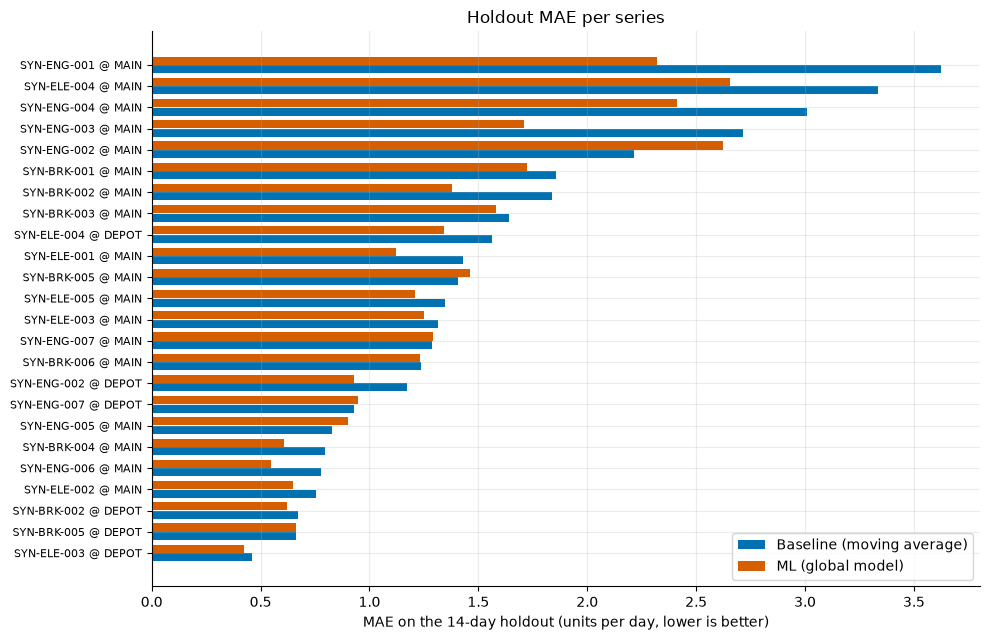

In [5]:
rows = []
for key, ev in result.per_series.items():
    rows.append({"series": label(key), "window": ev.baseline_window, "MA7": ev.mae_ma7, "MA14": ev.mae_ma14, "baseline": ev.mae_baseline,
                 "ML": ev.mae_ml, "selected": ev.selected, "nested": ev.nested_selected, "sigma": ev.sigma,
                 "steered": products[key[0]] in steered})
per_series = pd.DataFrame(rows).sort_values("baseline", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(per_series))
ax.barh(y + 0.2, per_series["baseline"], height=0.38, color=BASELINE, label="Baseline (moving average)")
ax.barh(y - 0.2, per_series["ML"], height=0.38, color=ML, label="ML (global model)")
ax.set_yticks(y, per_series["series"], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("MAE on the 14-day holdout (units per day, lower is better)")
ax.set_title("Holdout MAE per series")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [6]:
wins = (per_series["ML"] < per_series["baseline"]).sum()
print(f"ML beats the baseline on the holdout in {wins} of {len(per_series)} series; the baseline wins or ties in {len(per_series) - wins}:")
per_series[per_series["ML"] >= per_series["baseline"]][["series", "window", "baseline", "ML"]].round(2)

ML beats the baseline on the holdout in 18 of 24 series; the baseline wins or ties in 6:


,series,window,baseline,ML
4,SYN-ENG-002 @ MAIN,14,2.21,2.62
10,SYN-BRK-005 @ MAIN,14,1.41,1.46
13,SYN-ENG-007 @ MAIN,14,1.29,1.29
16,SYN-ENG-007 @ DEPOT,7,0.93,0.95
17,SYN-ENG-005 @ MAIN,14,0.83,0.90
22,SYN-BRK-005 @ DEPOT,14,0.66,0.66


In [7]:
print("Baseline window chosen on training days only:", per_series["window"].value_counts().sort_index().to_dict())
print(f"Selection: AI-003 picks ML for {result.selected_ml} series; the nested (honest) policy picks ML for {result.nested_selected_ml}.")
agree = (per_series["selected"] == per_series["nested"]).mean()
print(f"The two selections agree on only {100 * agree:.0f}% of series: with 14 noisy days, who 'wins' per series is largely luck.")

Baseline window chosen on training days only: {7: 5, 14: 19}
Selection: AI-003 picks ML for 18 series; the nested (honest) policy picks ML for 11.
The two selections agree on only 38% of series: with 14 noisy days, who 'wins' per series is largely luck.


### Sensitivity: the series the seed generator steered

For the SEED-007 demo scenarios the generator *shapes the last 12 days of demand* of five products
(four near their reorder point, one fast-growing) so they end at chosen stock levels. Those days are
not natural demand, and they fall inside the holdout. The table repeats the comparison without them.

In [8]:
from app.forecasting.metrics import summarise
keep = {k: ev for k, ev in result.per_series.items() if products[k[0]] not in steered}
pick = {"Baseline": lambda e: e.baseline, "ML": lambda e: e.ml_or_baseline, "Selected": lambda e: e.selected_forecast,
        "Selected, nested": lambda e: e.nested_forecast}
table = pd.DataFrame({
    name: {"all series": summarise({k: (e.actual, f(e)) for k, e in result.per_series.items()}).macro_mae,
           f"without {len(result.per_series) - len(keep)} steered series": summarise({k: (e.actual, f(e)) for k, e in keep.items()}).macro_mae}
    for name, f in pick.items()}).T
table.round(3)

,all series,without 5 steered series
Baseline,1.536,1.276
ML,1.317,1.175
Selected,1.294,1.145
"Selected, nested",1.414,1.212


## 3. Forecasts for the two demo products

Left: the holdout check (a forecast made the day before the grey band, compared with what happened).
Right: the production forecast for the next 30 days with the selected model's ±1.65σ band.
**The Cabin Air Filter is one of the steered products**: the generator shaped its last 12 days of demand to
land a demo stock level, so its holdout is synthetic demand shaping, not natural demand. The Timing Belt
Kit is the over-stocked demo product: low, lumpy demand, where a flat average is hard to beat.

In [9]:
import tempfile
from app.forecasting.service import ForecastService
from app.forecasting.training import train_forecasting
from app.registry import ModelRegistry
from app.forecasting.baseline import moving_average_forecast

registry = ModelRegistry(tempfile.mkdtemp())
outcome = train_forecasting(series, registry)
service = ForecastService(source, registry, tz_offset_hours=6)
sku_id = {v: k for k, v in products.items()}
demo = {"TREND_FAST: Cabin Air Filter (SYN-ENG-003)": (sku_id["SYN-ENG-003"], 1),
        "OVERSTOCKED: Timing Belt Kit (SYN-ENG-005)": (sku_id["SYN-ENG-005"], 1)}
print("model version:", outcome.version)

model version: forecast-20261101-f1cb5c15


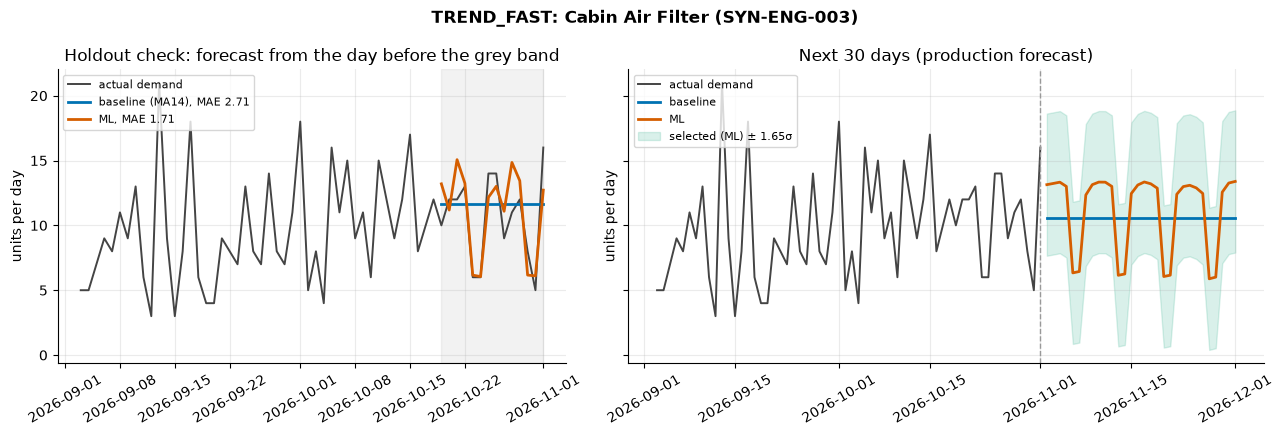

selected ML | baseline window 14 | mean 11.2/day | sigma 3.32 | holdout MAE baseline 2.71, ML 1.71


In [10]:
def show(title, key):
    ev = result.per_series[key]
    history = series[key]
    answer = service.forecast([key], 30)["results"][0]
    future = pd.DataFrame(answer["forecast"]); future["date"] = pd.to_datetime(future["date"])
    holdout_days = history.index[-14:]
    recent = history.iloc[-60:]

    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.25]}, sharey=True)
    left.plot(recent.index, recent.values, color=ACTUAL, lw=1.4, label="actual demand")
    left.plot(holdout_days, ev.baseline, color=BASELINE, lw=2, label=f"baseline (MA{ev.baseline_window}), MAE {ev.mae_baseline:.2f}")
    left.plot(holdout_days, ev.ml, color=ML, lw=2, label=f"ML, MAE {ev.mae_ml:.2f}")
    left.axvspan(holdout_days[0], holdout_days[-1], color="#999999", alpha=0.12)
    left.set_title("Holdout check: forecast from the day before the grey band")
    left.legend(loc="upper left", fontsize=8)

    right.plot(recent.index, recent.values, color=ACTUAL, lw=1.4, label="actual demand")
    right.plot(future["date"], future["baseline"], color=BASELINE, lw=2, label="baseline")
    right.plot(future["date"], future["ml"], color=ML, lw=2, label="ML")
    chosen = future["mean"].to_numpy()
    right.fill_between(future["date"], np.clip(chosen - 1.65 * answer["sigma"], 0, None), chosen + 1.65 * answer["sigma"], color=SELECTED, alpha=0.15,
                       label=f"selected ({answer['selectedModel']}) ± 1.65σ")
    right.axvline(history.index[-1], color="#999999", ls="--", lw=1)
    right.set_title("Next 30 days (production forecast)")
    right.legend(loc="upper left", fontsize=8)
    for axis in (left, right):
        axis.set_ylabel("units per day"); axis.tick_params(axis="x", rotation=30)
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    plt.show()
    print(f"selected {answer['selectedModel']} | baseline window {answer['baselineWindow']} | mean {answer['dailyMean']:.1f}/day | sigma {answer['sigma']:.2f} | "
          f"holdout MAE baseline {answer['metrics']['maeBaseline']:.2f}, ML {answer['metrics']['maeMl']:.2f}")

show(list(demo)[0], list(demo.values())[0])

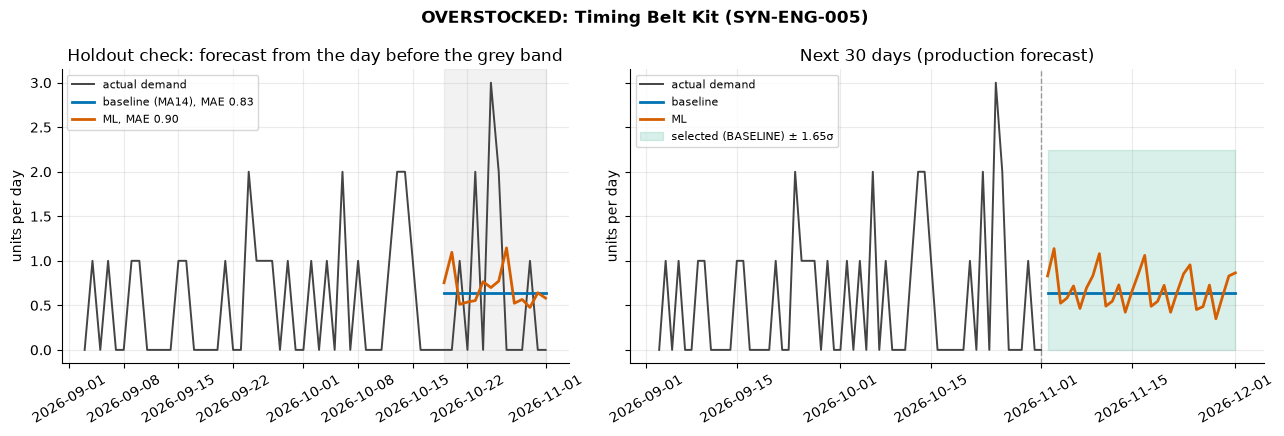

selected BASELINE | baseline window 14 | mean 0.6/day | sigma 0.97 | holdout MAE baseline 0.83, ML 0.90


In [11]:
show(list(demo)[1], list(demo.values())[1])

## 4. What this does and does not show

* **Synthetic data.** Demand is Poisson noise around a weekday pattern and a trend. The model finding
  that structure is expected; real demand has promotions, stock-outs, returns and shocks.
* **One 14-day holdout.** Per-series MAEs rest on 14 noisy points. The comparison across all series is
  more reliable than any single series, and the nested estimate is the figure to quote for the selection policy.
* **Demand is observed issues.** When stock hits zero, no issue is recorded, so true demand is under-stated
  (censoring). The synthetic data has very few stock-outs; real data may not.
* **No outlier cleaning.** The eight injected anomalies stay in the training series; with ~2,700 issues
  their effect is small, but it is not zero.
* **Sigma** is the RMSE of the selected model's 14 holdout residuals, floored at the Poisson spread. It is a
  rough, noisy estimate and feeds the safety stock (AI-004).